# BÀI TẬP LỚN HỌC MÁY ỨNG DỤNG: DỰ BÁO VÀ NGĂN CHẶN RỜI BỎ KHÁCH HÀNG NGÂN HÀNG
# (BANK CUSTOMER CHURN PREDICTION & RETENTION STRATEGY)
### Sinh viên thực hiện: Hoàng Hữu Bảo
### Doanh nghiệp giả định: EuroVanguard Bank (France, Germany, Spain)
**Quy trình chuẩn mực:** CRISP-DM & Gartner's 4 Analytics Levels (Descriptive $\rightarrow$ Diagnostic $\rightarrow$ Predictive $\rightarrow$ Prescriptive)

---


## Dataset Overview

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import json
import random
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
plt.style.use('ggplot')

onefig_size = (10, 4)
multifigs_size = (12, 4)

# Cấu hình thư mục lưu biểu đồ và mô hình
FIGURES_DIR = os.path.join('reports', 'figures')
MODELS_DIR = 'models'
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)


In [2]:
# Nạp tập dữ liệu gốc (Hỗ trợ linh hoạt đường dẫn ở cả thư mục gốc và thư mục con)
if os.path.exists('Customer-Churn-Records.csv'):
    DATA_PATH = 'Customer-Churn-Records.csv'
elif os.path.exists(os.path.join('data', 'raw', 'Customer-Churn-Records.csv')):
    DATA_PATH = os.path.join('data', 'raw', 'Customer-Churn-Records.csv')
elif os.path.exists(os.path.join('..', 'data', 'raw', 'Customer-Churn-Records.csv')):
    DATA_PATH = os.path.join('..', 'data', 'raw', 'Customer-Churn-Records.csv')
else:
    DATA_PATH = 'Customer-Churn-Records.csv'

original_df = pd.read_csv(DATA_PATH)
print(f"Đã nạp thành công bộ dữ liệu: {original_df.shape[0]:,} dòng x {original_df.shape[1]} cột")
original_df.head()


Đã nạp thành công bộ dữ liệu: 10,000 dòng x 18 cột


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
original_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [4]:
original_df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


Kiểm tra tập giá trị của các biến phân loại (Categorical features):

In [5]:
print("Geography values:     ", set(original_df['Geography']))
print("Gender values:        ", set(original_df['Gender']))
print("NumOfProducts values: ", set(original_df['NumOfProducts']))
print("HasCrCard values:     ", set(original_df['HasCrCard']))
print("IsActiveMember values:", set(original_df['IsActiveMember']))
print("Card Type values:     ", set(original_df['Card Type']))
print("Satisfaction values:  ", set(original_df['Satisfaction Score']))
print("Complain values:      ", set(original_df['Complain']))
print("Target (Exited):      ", set(original_df['Exited']))


Geography values:      {'Germany', 'Spain', 'France'}
Gender values:         {'Female', 'Male'}
NumOfProducts values:  {1, 2, 3, 4}
HasCrCard values:      {0, 1}
IsActiveMember values: {0, 1}
Card Type values:      {'PLATINUM', 'DIAMOND', 'GOLD', 'SILVER'}
Satisfaction values:   {1, 2, 3, 4, 5}
Complain values:       {0, 1}
Target (Exited):       {0, 1}


## Data Integration
**Tuyên bố Tích hợp Dữ liệu Đơn nguồn (Single-Source Data Integration Declaration):**
Tập dữ liệu `Customer-Churn-Records.csv` bao gồm 10,000 hồ sơ khách hàng là nguồn dữ liệu duy nhất và toàn vẹn, được trích xuất đồng bộ từ hệ thống quản trị ngân hàng lõi (Core Banking System) và quản lý quan hệ khách hàng (CRM) của EuroVanguard Bank. Do toàn bộ 18 trường thông tin (từ nhân khẩu học, giao dịch tiền gửi, thẻ tín dụng đến khiếu nại dịch vụ) đã được tích hợp nhất quán theo định danh duy nhất `CustomerId`, dự án không yêu cầu sáp nhập (merge/join) thêm từ các nguồn dữ liệu bên ngoài.


## Data Cleaning

### Chuẩn hóa Tên Cột & Dọn dẹp Khoảng trắng

In [6]:
df_clean = original_df.copy()

# Chuẩn hóa tên cột: loại bỏ khoảng trắng thừa và thay khoảng trắng bằng dấu gạch dưới
df_clean.columns = [c.strip().replace(' ', '_') for c in df_clean.columns]
print("Danh sách các cột sau chuẩn hóa:", list(df_clean.columns))


Danh sách các cột sau chuẩn hóa: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction_Score', 'Card_Type', 'Point_Earned']


### Data Duplication

In [7]:
dup_rows = df_clean.duplicated().sum()
dup_customer_ids = df_clean['CustomerId'].duplicated().sum()
print(f"Số dòng trùng lặp hoàn toàn: {dup_rows}")
print(f"Số ID khách hàng (CustomerId) bị trùng: {dup_customer_ids}")


Số dòng trùng lặp hoàn toàn: 0
Số ID khách hàng (CustomerId) bị trùng: 0


### Missing Data

In [8]:
missing_df = pd.DataFrame({
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Pct': (df_clean.isnull().sum() / len(df_clean)) * 100
})
display(missing_df[missing_df['Missing_Count'] > 0] if missing_df['Missing_Count'].sum() > 0 else "Không có giá trị khuyết thiếu (0 Missing Values)!")


'Không có giá trị khuyết thiếu (0 Missing Values)!'

### Xử lý Ký tự Lạ (Encoding Anomalies) & Kiểm tra Miền Giá trị Nghiệp vụ

In [9]:
# 1. Phát hiện và làm sạch lỗi ký tự lạ '?' trong cột Surname do lỗi mã hóa UTF-8
raw_surnames = df_clean['Surname'].astype(str)
encoding_issue_mask = raw_surnames.str.contains(r'\?', regex=True)
df_clean['Surname_Encoding_Issue'] = encoding_issue_mask.astype(int)
df_clean['Surname'] = raw_surnames.str.replace(r'\?', '', regex=True).str.strip()
print(f"Đã phát hiện và làm sạch {encoding_issue_mask.sum()} họ tên khách hàng bị lỗi ký tự '?'.")

# 2. Kiểm tra miền giá trị nghiệp vụ (Domain Range Validation)
checks = {
    'CreditScore [350-850]': df_clean['CreditScore'].between(350, 850).all(),
    'Age [18-100]': df_clean['Age'].between(18, 100).all(),
    'Tenure [0-10]': df_clean['Tenure'].between(0, 10).all(),
    'Balance >= 0': (df_clean['Balance'] >= 0).all(),
    'NumOfProducts in [1,2,3,4]': df_clean['NumOfProducts'].isin([1, 2, 3, 4]).all(),
    'HasCrCard in [0,1]': df_clean['HasCrCard'].isin([0, 1]).all(),
    'IsActiveMember in [0,1]': df_clean['IsActiveMember'].isin([0, 1]).all(),
    'EstimatedSalary >= 0': (df_clean['EstimatedSalary'] >= 0).all(),
    'Satisfaction_Score [1-5]': df_clean['Satisfaction_Score'].between(1, 5).all(),
    'Point_Earned >= 0': (df_clean['Point_Earned'] >= 0).all(),
    'Complain in [0,1]': df_clean['Complain'].isin([0, 1]).all(),
    'Exited in [0,1]': df_clean['Exited'].isin([0, 1]).all()
}
for rule, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {rule}")


Đã phát hiện và làm sạch 92 họ tên khách hàng bị lỗi ký tự '?'.
[PASS] CreditScore [350-850]
[PASS] Age [18-100]
[PASS] Tenure [0-10]
[PASS] Balance >= 0
[PASS] NumOfProducts in [1,2,3,4]
[PASS] HasCrCard in [0,1]
[PASS] IsActiveMember in [0,1]
[PASS] EstimatedSalary >= 0
[PASS] Satisfaction_Score [1-5]
[PASS] Point_Earned >= 0
[PASS] Complain in [0,1]
[PASS] Exited in [0,1]


## Exploratory Data Analysis

### Prediction Variable
**Phân tích Biến Mục tiêu (`Exited`) & Hệ thống Mục tiêu Kép (Dual Baseline Framework):**
Khác biệt với phân tích thông thường chỉ nhìn vào số lượng người (Headcount Churn), tại EuroVanguard Bank chúng ta gắn kết trực tiếp với **Khối lượng Tiền gửi Huy động Rủi ro (Deposit Volume at Risk)**.


1. Tỷ lệ Rời bỏ Đầu người (Headcount Churn):    20.38% (2,038 / 10,000 khách hàng)
2. Tỷ lệ Thất thoát Tiền gửi (Balance at Risk): 24.28% (185.68M EUR / 764.86M EUR)


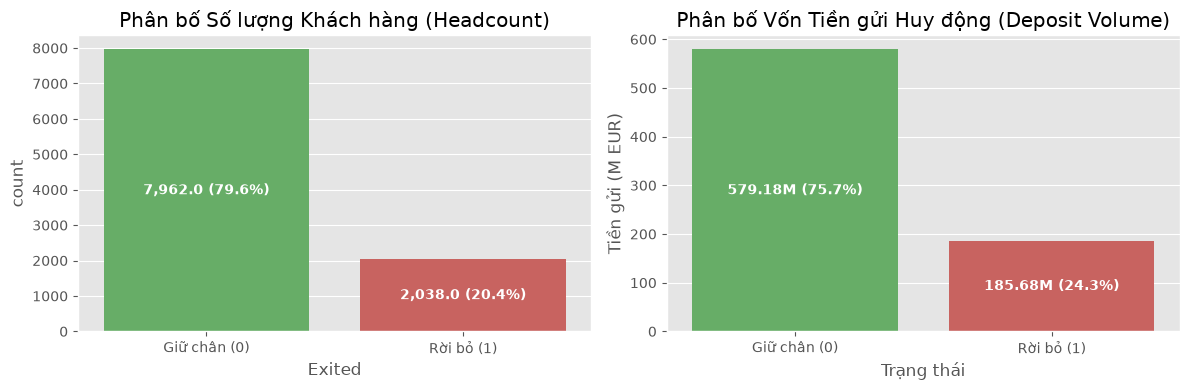

In [10]:
total_customers = len(df_clean)
churned_customers = df_clean['Exited'].sum()
headcount_churn_pct = (churned_customers / total_customers) * 100

total_balance = df_clean['Balance'].sum()
churned_balance = df_clean[df_clean['Exited'] == 1]['Balance'].sum()
balance_churn_pct = (churned_balance / total_balance) * 100

print(f"1. Tỷ lệ Rời bỏ Đầu người (Headcount Churn):    {headcount_churn_pct:.2f}% ({churned_customers:,} / {total_customers:,} khách hàng)")
print(f"2. Tỷ lệ Thất thoát Tiền gửi (Balance at Risk): {balance_churn_pct:.2f}% ({churned_balance/1e6:.2f}M EUR / {total_balance/1e6:.2f}M EUR)")

# Trực quan hóa Target
fig, ax = plt.subplots(1, 2, figsize=multifigs_size)
sns.countplot(x='Exited', data=df_clean, palette=['#5cb85c', '#d9534f'], ax=ax[0])
ax[0].set_title("Phân bố Số lượng Khách hàng (Headcount)")
ax[0].set_xticklabels(['Giữ chân (0)', 'Rời bỏ (1)'])
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():,} ({p.get_height()/total_customers*100:.1f}%)",
                   (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold')

churn_bal_df = pd.DataFrame({
    'Trạng thái': ['Giữ chân (0)', 'Rời bỏ (1)'],
    'Tiền gửi (M EUR)': [(total_balance - churned_balance)/1e6, churned_balance/1e6]
})
sns.barplot(x='Trạng thái', y='Tiền gửi (M EUR)', data=churn_bal_df, palette=['#5cb85c', '#d9534f'], ax=ax[1])
ax[1].set_title("Phân bố Vốn Tiền gửi Huy động (Deposit Volume)")
for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.2f}M ({p.get_height()/(total_balance/1e6)*100:.1f}%)",
                   (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_01_target_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()


### Categorical Variables
*(Trực quan hóa cấu trúc 3 biểu đồ con theo phong cách chuẩn mực của Giảng viên: `histplot`, `barplot`, và `boxplot`)*


--- 1. PHÂN TÍCH ĐỊA LÝ (GEOGRAPHY) ---


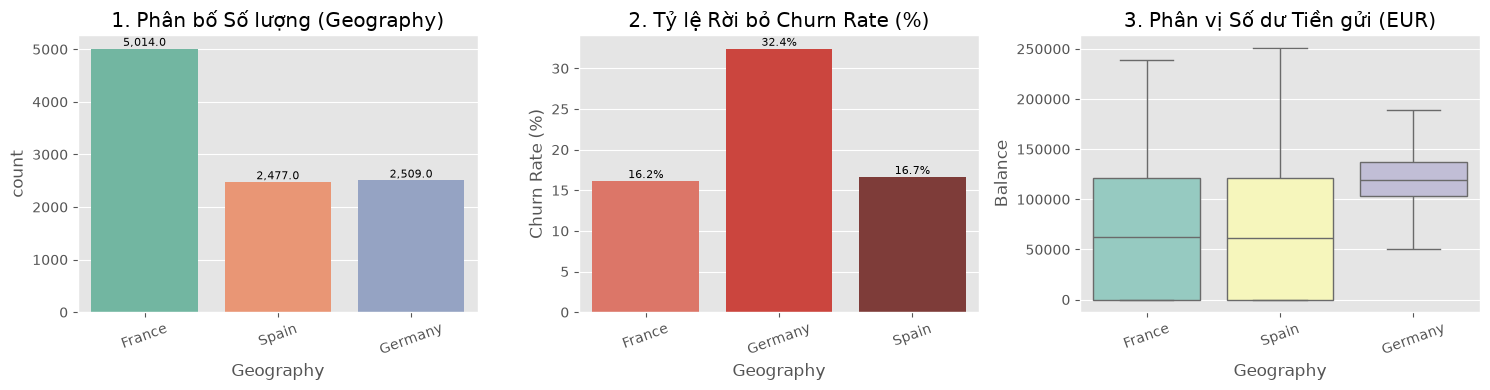

--- 2. PHÂN TÍCH SỐ LƯỢNG SẢN PHẨM (NUMOFPRODUCTS) ---


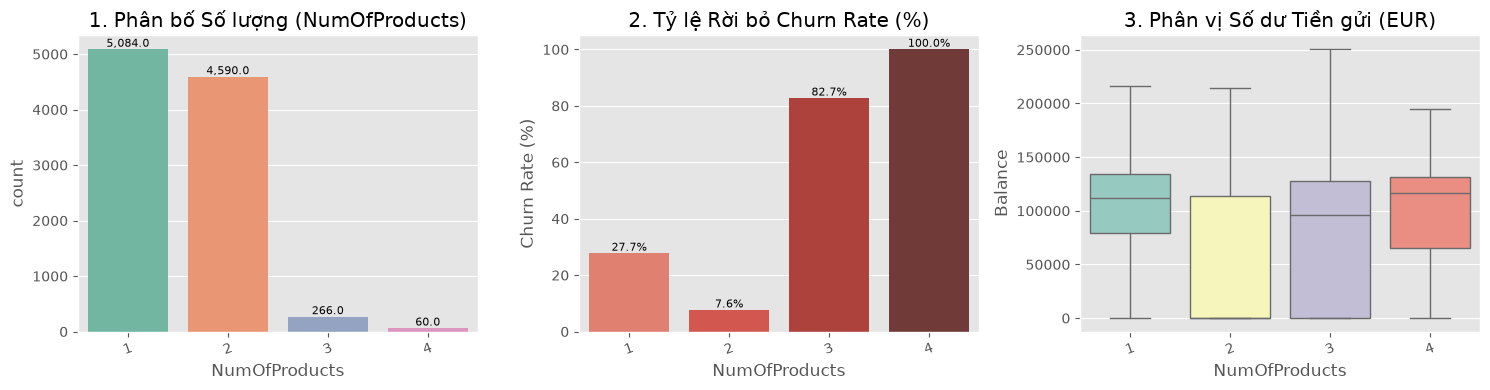

--- 3. PHÂN TÍCH GIỚI TÍNH (GENDER) ---


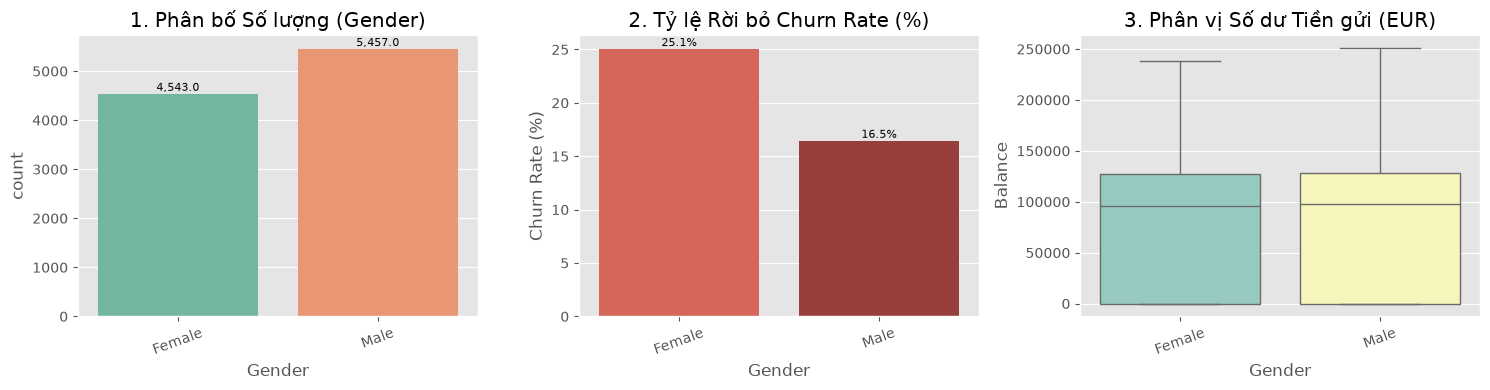

--- 4. PHÂN TÍCH TRẠNG THÁI HOẠT ĐỘNG (ISACTIVEMEMBER) ---


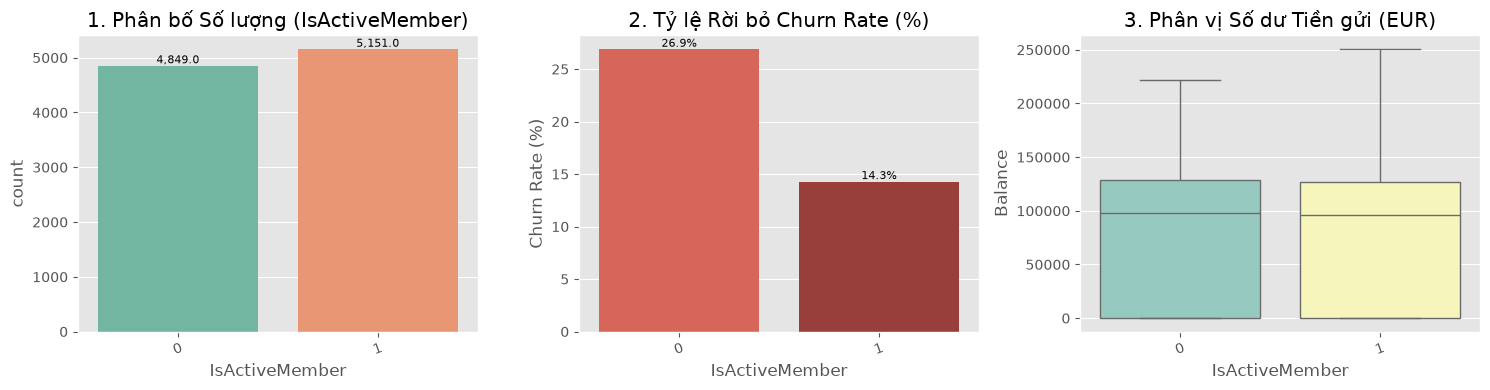

In [11]:
def plot_categorical_analysis_3subfigs(df, cat_col, target_col='Exited', balance_col='Balance'):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Subfig 1: Phân bố số lượng (Count / Distribution)
    sns.countplot(x=cat_col, data=df, ax=axes[0], palette='Set2')
    axes[0].set_title(f"1. Phân bố Số lượng ({cat_col})")
    axes[0].tick_params(axis='x', rotation=20)
    for p in axes[0].patches:
        h = p.get_height()
        if h > 0:
            axes[0].annotate(f"{h:,}", (p.get_x() + p.get_width()/2., h),
                             ha='center', va='bottom', fontsize=8)
    
    # Subfig 2: Tỷ lệ Churn theo nhóm (Churn Rate %)
    churn_rates = df.groupby(cat_col)[target_col].mean().reset_index()
    churn_rates['Churn_Pct'] = churn_rates[target_col] * 100
    sns.barplot(x=cat_col, y='Churn_Pct', data=churn_rates, ax=axes[1], palette='Reds_d')
    axes[1].set_title(f"2. Tỷ lệ Rời bỏ Churn Rate (%)")
    axes[1].set_ylabel("Churn Rate (%)")
    axes[1].tick_params(axis='x', rotation=20)
    for p in axes[1].patches:
        h = p.get_height()
        if h > 0:
            axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width()/2., h),
                             ha='center', va='bottom', fontsize=8)
            
    # Subfig 3: Phân bố tiền gửi theo nhóm (Balance Distribution)
    sns.boxplot(x=cat_col, y=balance_col, data=df, ax=axes[2], palette='Set3', showfliers=False)
    axes[2].set_title(f"3. Phân vị Số dư Tiền gửi (EUR)")
    axes[2].tick_params(axis='x', rotation=20)
    
    plt.tight_layout()
    plt.show()

# 1. Phân tích Địa lý (Geography)
print("--- 1. PHÂN TÍCH ĐỊA LÝ (GEOGRAPHY) ---")
plot_categorical_analysis_3subfigs(df_clean, 'Geography')

# 2. Phân tích Số lượng Sản phẩm (NumOfProducts)
print("--- 2. PHÂN TÍCH SỐ LƯỢNG SẢN PHẨM (NUMOFPRODUCTS) ---")
plot_categorical_analysis_3subfigs(df_clean, 'NumOfProducts')

# 3. Phân tích Giới tính (Gender)
print("--- 3. PHÂN TÍCH GIỚI TÍNH (GENDER) ---")
plot_categorical_analysis_3subfigs(df_clean, 'Gender')

# 4. Phân tích Trạng thái Hoạt động (IsActiveMember)
print("--- 4. PHÂN TÍCH TRẠNG THÁI HOẠT ĐỘNG (ISACTIVEMEMBER) ---")
plot_categorical_analysis_3subfigs(df_clean, 'IsActiveMember')


### Data Visualization

#### Correlation Matrix
Ma trận tương quan Pearson giữa tất cả các biến số và biến nhị phân:


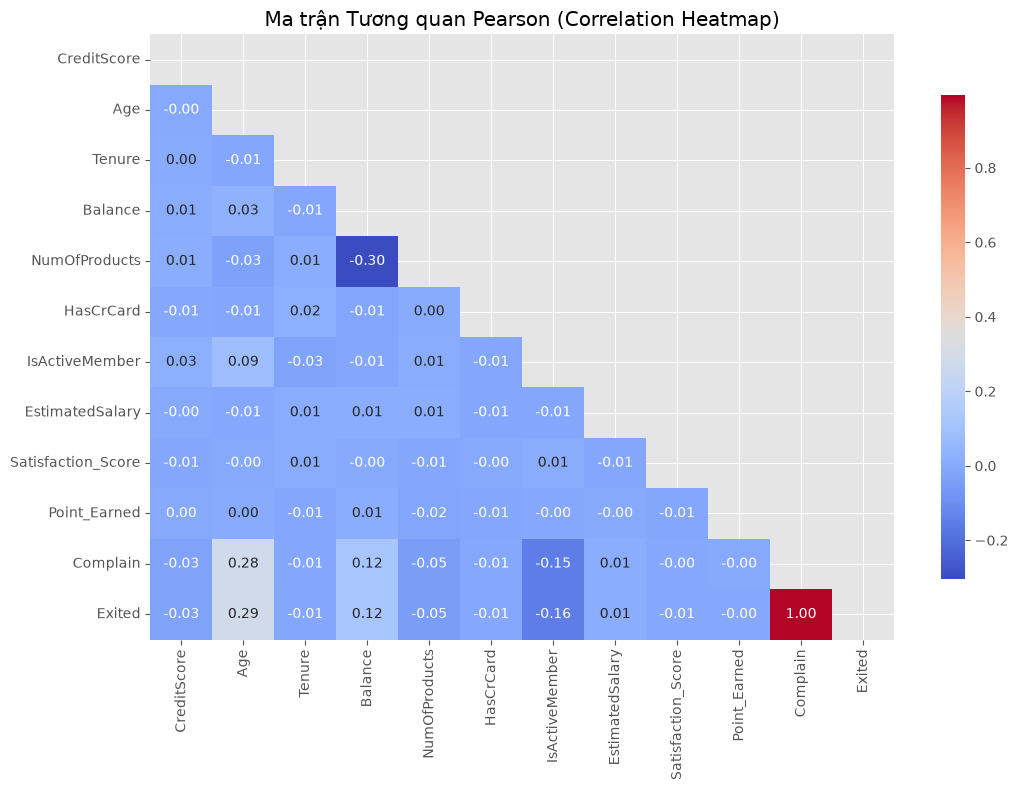

In [12]:
numeric_cols = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
    'IsActiveMember', 'EstimatedSalary', 'Satisfaction_Score', 'Point_Earned',
    'Complain', 'Exited'
]
corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, cbar_kws={'shrink': .8})
plt.title("Ma trận Tương quan Pearson (Correlation Heatmap)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_09_correlation_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()


#### Tâm chấn Đa biến 1: Thị trường Đức (`Geography` × `IsActiveMember` × `Balance`)
Giải mã bí ẩn tại sao chi nhánh Đức có tỷ lệ rời bỏ gấp đôi Pháp và Tây Ban Nha và gây thất thoát hơn 50% tiền gửi:


,Geography,IsActiveMember,Total,Churned,Churn_Rate_Pct,Total_Balance_M_EUR,Churn_Balance_M_EUR
0,France,0,2423,513,21.17,153.77,37.28
1,France,1,2591,298,11.50,157.56,20.48
2,Germany,0,1261,518,41.08,150.80,62.27
3,Germany,1,1248,296,23.72,149.60,35.71
4,Spain,0,1165,272,23.35,69.45,19.02
5,Spain,1,1312,141,10.75,83.67,10.93


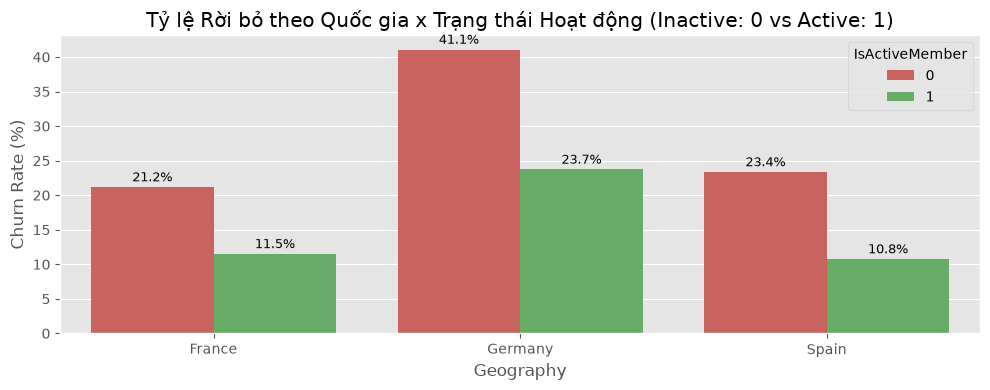

In [13]:
geo_summary = df_clean.groupby(['Geography', 'IsActiveMember'])['Exited'].agg(
    Total='count',
    Churned='sum',
    Churn_Rate_Pct=lambda x: round(x.mean() * 100, 2),
    Total_Balance_M_EUR=lambda x: round(df_clean.loc[x.index, 'Balance'].sum() / 1e6, 2),
    Churn_Balance_M_EUR=lambda x: round(df_clean.loc[x.index][df_clean.loc[x.index, 'Exited'] == 1]['Balance'].sum() / 1e6, 2)
).reset_index()

display(geo_summary)

plt.figure(figsize=onefig_size)
sns.barplot(x='Geography', y='Churn_Rate_Pct', hue='IsActiveMember', data=geo_summary, palette=['#d9534f', '#5cb85c'])
plt.title("Tỷ lệ Rời bỏ theo Quốc gia x Trạng thái Hoạt động (Inactive: 0 vs Active: 1)")
plt.ylabel("Churn Rate (%)")
for p in plt.gca().patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        plt.gca().annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_10_multivariate_germany_active.png'), dpi=300, bbox_inches='tight')
plt.show()


#### Tâm chấn Đa biến 2: Bẫy Bán chéo theo Độ tuổi (`Age Group` × `NumOfProducts`)
Đường cong chữ U ngược: 2 sản phẩm là tối ưu, 3-4 sản phẩm kích hoạt làn sóng rời bỏ ồ ạt:


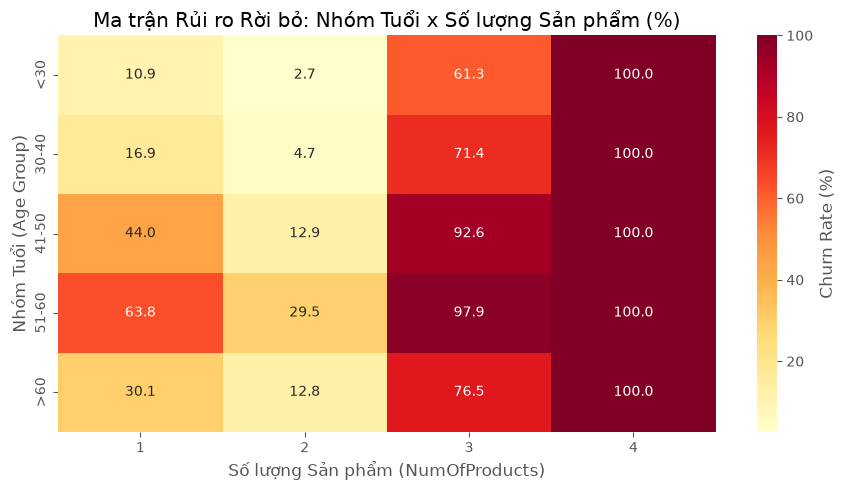

NumOfProducts,1,2,3,4
Age_Binned,,,,
<30,10.90,2.66,61.29,100.0
30-40,16.85,4.72,71.43,100.0
41-50,44.03,12.95,92.55,100.0
51-60,63.80,29.54,97.87,100.0
>60,30.12,12.76,76.47,100.0


In [14]:
df_clean['Age_Binned'] = pd.cut(df_clean['Age'], bins=[18, 30, 40, 50, 60, 100], labels=['<30', '30-40', '41-50', '51-60', '>60'])
pivot_age_prod = df_clean.pivot_table(index='Age_Binned', columns='NumOfProducts', values='Exited', aggfunc='mean') * 100

plt.figure(figsize=(9, 5))
sns.heatmap(pivot_age_prod, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Churn Rate (%)'})
plt.title("Ma trận Rủi ro Rời bỏ: Nhóm Tuổi x Số lượng Sản phẩm (%)")
plt.xlabel("Số lượng Sản phẩm (NumOfProducts)")
plt.ylabel("Nhóm Tuổi (Age Group)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_11_multivariate_age_products.png'), dpi=300, bbox_inches='tight')
plt.show()

display(pivot_age_prod.round(2))


#### Tâm chấn Đa biến 3: Nghịch lý Khiếu nại (`Complain` × `Satisfaction_Score`) & Rò rỉ Dữ liệu
Minh chứng thực nghiệm: Khách hàng có khiếu nại (`Complain = 1`) rời bỏ tới 99.5% bất kể họ chấm điểm khảo sát hài lòng 1 sao hay 5 sao:


Bảng thống kê tỷ lệ rời bỏ của nhóm có khiếu nại (Complain = 1):


,Complain,Satisfaction_Score,Total,Churned,Churn_Rate_Pct
5,1,1,387,386,99.74
6,1,2,438,437,99.77
7,1,3,406,401,98.77
8,1,4,413,413,100.00
9,1,5,400,397,99.25


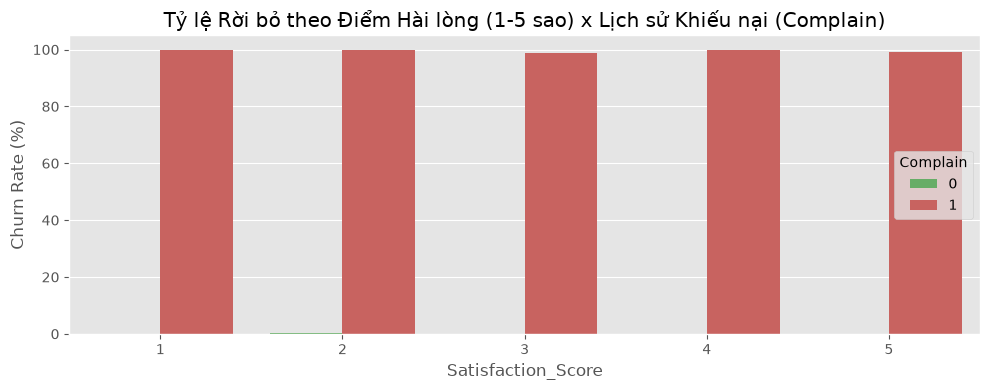

In [15]:
paradox = df_clean.groupby(['Complain', 'Satisfaction_Score'])['Exited'].agg(
    Total='count',
    Churned='sum',
    Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)
).reset_index()

print("Bảng thống kê tỷ lệ rời bỏ của nhóm có khiếu nại (Complain = 1):")
display(paradox[paradox['Complain'] == 1])

plt.figure(figsize=onefig_size)
sns.barplot(x='Satisfaction_Score', y='Churn_Rate_Pct', hue='Complain', data=paradox, palette=['#5cb85c', '#d9534f'])
plt.title("Tỷ lệ Rời bỏ theo Điểm Hài lòng (1-5 sao) x Lịch sử Khiếu nại (Complain)")
plt.ylabel("Churn Rate (%)")
plt.legend(title='Complain', loc='center right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_12_complain_satisfaction_paradox.png'), dpi=300, bbox_inches='tight')
plt.show()


#### Kiểm định Thống kê & Xếp hạng Giá trị Thông tin (Information Value - IV)

In [16]:
def calculate_woe_iv_standalone(df, feature, target):
    total_good = (df[target] == 0).sum()
    total_bad = (df[target] == 1).sum()
    grouped = df.groupby(feature, observed=False)[target].agg(
        total='count',
        bad='sum'
    ).reset_index()
    grouped['good'] = grouped['total'] - grouped['bad']
    grouped['dist_good'] = grouped['good'].clip(lower=0.5) / total_good
    grouped['dist_bad'] = grouped['bad'].clip(lower=0.5) / total_bad
    grouped['WOE'] = np.log(grouped['dist_good'] / grouped['dist_bad'])
    grouped['IV'] = (grouped['dist_good'] - grouped['dist_bad']) * grouped['WOE']
    iv_total = grouped['IV'].sum()
    return grouped, iv_total

iv_results = []
test_features = ['Geography', 'Gender', 'Tenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Card_Type', 'Satisfaction_Score', 'Complain']

for f in test_features:
    _, iv_val = calculate_woe_iv_standalone(df_clean, f, 'Exited')
    iv_results.append({'Feature': f, 'IV': round(iv_val, 4)})

# Binned IV cho biến liên tục
df_clean['Age_Binned_5'] = pd.qcut(df_clean['Age'], q=5, duplicates='drop')
_, iv_age = calculate_woe_iv_standalone(df_clean, 'Age_Binned_5', 'Exited')
iv_results.append({'Feature': 'Age (binned)', 'IV': round(iv_age, 4)})

df_clean['Balance_Binned_5'] = pd.qcut(df_clean['Balance'], q=5, duplicates='drop')
_, iv_bal = calculate_woe_iv_standalone(df_clean, 'Balance_Binned_5', 'Exited')
iv_results.append({'Feature': 'Balance (binned)', 'IV': round(iv_bal, 4)})

iv_df = pd.DataFrame(iv_results).sort_values(by='IV', ascending=False).reset_index(drop=True)
print("=== BẢNG XẾP HẠNG GIÁ TRỊ THÔNG TIN (INFORMATION VALUE - IV) ===")
display(iv_df)


=== BẢNG XẾP HẠNG GIÁ TRỊ THÔNG TIN (INFORMATION VALUE - IV) ===


,Feature,IV
0,Complain,12.8685
1,NumOfProducts,0.9828
2,Age (binned),0.7442
3,Geography,0.1680
4,IsActiveMember,0.1536
5,Balance (binned),0.0922
6,Gender,0.0694
7,Tenure,0.0088
8,Card_Type,0.0031
9,Satisfaction_Score,0.0023


#### Kiểm tra Đa cộng tuyến (Variance Inflation Factor - VIF)

In [17]:
from sklearn.linear_model import LinearRegression

def calculate_vif_robust(df, numeric_cols):
    vif_data = []
    X = df[numeric_cols].dropna()
    for col in numeric_cols:
        y_col = X[col]
        X_other = X.drop(columns=[col])
        reg = LinearRegression().fit(X_other, y_col)
        r_sq = reg.score(X_other, y_col)
        vif = 1.0 / (1.0 - r_sq) if r_sq < 0.9999 else 9999.0
        vif_data.append({'Feature': col, 'VIF': round(vif, 3)})
    return pd.DataFrame(vif_data).sort_values(by='VIF', ascending=False).reset_index(drop=True)

vif_df = calculate_vif_robust(df_clean, ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Satisfaction_Score', 'Point_Earned'])
print("=== HỆ SỐ PHÓNG ĐẠI PHƯƠNG SAI (VIF) ===")
display(vif_df)


=== HỆ SỐ PHÓNG ĐẠI PHƯƠNG SAI (VIF) ===


,Feature,VIF
0,NumOfProducts,1.104
1,Balance,1.103
2,Tenure,1.001
3,Age,1.001
4,Satisfaction_Score,1.001
5,EstimatedSalary,1.001
6,Point_Earned,1.001
7,CreditScore,1.000


## Feature Engineering
Dựa trên các căn cứ chẩn đoán từ EDA, 6 đặc trưng kỹ thuật nghiệp vụ mới được thiết lập (hoàn toàn theo cơ chế xác định từng dòng độc lập - Row-wise, ngăn chặn 100% rò rỉ dữ liệu):
1. **`IsZeroBalance`:** Cờ nhị phân (1 nếu Balance == 0.0, ngược lại 0).
2. **`Balance_To_Salary_Ratio`:** Tỷ lệ số dư tiền gửi trên thu nhập (`Balance / (Salary + 1)`).
3. **`Products_Per_Tenure`:** Tốc độ mua thêm sản phẩm theo thời gian gắn bó (`NumOfProducts / (Tenure + 1)`).
4. **`Product_Holding_Risk_Tier`:** Phân tầng rủi ro bán chéo (`Optimal` cho 2 sp, `Moderate_Risk` cho 1 sp, `Extreme_Danger` cho 3-4 sp).
5. **`Age_Lifecycle_Stage`:** Giai đoạn vòng đời (`<30`, `30-40`, `41-50`, `51-60`, `>60`).
6. **`Engagement_Score`:** Điểm tương tác tổng hợp từ hoạt động, thẻ tín dụng và số lượng sản phẩm.


In [18]:
df_fe = df_clean.copy()

# 1. IsZeroBalance
df_fe['IsZeroBalance'] = (df_fe['Balance'] == 0.0).astype(int)

# 2. Balance_To_Salary_Ratio
df_fe['Balance_To_Salary_Ratio'] = np.round(df_fe['Balance'] / (df_fe['EstimatedSalary'] + 1.0), 4)

# 3. Products_Per_Tenure
df_fe['Products_Per_Tenure'] = np.round(df_fe['NumOfProducts'] / (df_fe['Tenure'] + 1.0), 4)

# 4. Product_Holding_Risk_Tier
def get_risk_tier(n):
    if n == 2:
        return 'Optimal'
    elif n == 1:
        return 'Moderate_Risk'
    else:
        return 'Extreme_Danger'
df_fe['Product_Holding_Risk_Tier'] = df_fe['NumOfProducts'].apply(get_risk_tier)

# 5. Age_Lifecycle_Stage
df_fe['Age_Lifecycle_Stage'] = pd.cut(df_fe['Age'], bins=[0, 30, 40, 50, 60, 150], labels=['<30', '30-40', '41-50', '51-60', '>60']).astype(str)

# 6. Engagement_Score
df_fe['Engagement_Score'] = (df_fe['IsActiveMember'] * 2 + df_fe['HasCrCard'] * 1 + (df_fe['NumOfProducts'] == 2).astype(int) * 1).astype(int)

print(f"Kích thước sau Feature Engineering: {df_fe.shape[0]:,} dòng x {df_fe.shape[1]} cột")
df_fe[['CustomerId', 'Balance', 'IsZeroBalance', 'Balance_To_Salary_Ratio', 'Products_Per_Tenure', 'Product_Holding_Risk_Tier', 'Age_Lifecycle_Stage', 'Engagement_Score']].head()


Kích thước sau Feature Engineering: 10,000 dòng x 28 cột


,CustomerId,Balance,IsZeroBalance,Balance_To_Salary_Ratio,Products_Per_Tenure,Product_Holding_Risk_Tier,Age_Lifecycle_Stage,Engagement_Score
0,15634602,0.00,1,0.0000,0.3333,Moderate_Risk,41-50,3
1,15647311,83807.86,0,0.7447,0.5000,Moderate_Risk,41-50,2
2,15619304,159660.80,0,1.4014,0.3333,Extreme_Danger,41-50,1
3,15701354,0.00,1,0.0000,1.0000,Optimal,30-40,1
4,15737888,125510.82,0,1.5870,0.3333,Moderate_Risk,41-50,3


## Experiment

### Prepare Train Test Dataset
Phân chia 3 tập chuẩn hóa: **70% Train (7,000 dòng)**, **15% Validation (1,500 dòng)**, và **15% Test (1,500 dòng)** theo cơ chế phân tầng (Stratified) trên biến mục tiêu `Exited`.


In [19]:
from sklearn.model_selection import train_test_split

target_col = 'Exited'
feature_cols_all = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
    'IsActiveMember', 'EstimatedSalary', 'Satisfaction_Score', 'Point_Earned',
    'IsZeroBalance', 'Balance_To_Salary_Ratio', 'Products_Per_Tenure', 'Engagement_Score',
    'Geography', 'Gender', 'Card_Type', 'Product_Holding_Risk_Tier', 'Age_Lifecycle_Stage'
]

# Tách Train (70%) và Phần tạm (30%)
train_df, temp_df = train_test_split(df_fe, test_size=0.30, stratify=df_fe[target_col], random_state=42)

# Tách Phần tạm thành Validation (15%) và Test (15%)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df[target_col], random_state=42)

print(f"Tập Huấn luyện (Train): {len(train_df):,} dòng (Tỷ lệ Churn: {train_df[target_col].mean()*100:.2f}%)")
print(f"Tập Thẩm định (Val):    {len(val_df):,} dòng (Tỷ lệ Churn: {val_df[target_col].mean()*100:.2f}%)")
print(f"Tập Kiểm thử (Test):   {len(test_df):,} dòng (Tỷ lệ Churn: {test_df[target_col].mean()*100:.2f}%)")

# Lưu trữ các tập dữ liệu đã chuẩn hóa vào data/processed
os.makedirs(os.path.join('data', 'processed'), exist_ok=True)
train_df.to_csv(os.path.join('data', 'processed', 'train.csv'), index=False)
val_df.to_csv(os.path.join('data', 'processed', 'val.csv'), index=False)
test_df.to_csv(os.path.join('data', 'processed', 'test.csv'), index=False)
df_fe.to_csv(os.path.join('data', 'processed', 'full_engineered.csv'), index=False)


Tập Huấn luyện (Train): 7,000 dòng (Tỷ lệ Churn: 20.39%)
Tập Thẩm định (Val):    1,500 dòng (Tỷ lệ Churn: 20.40%)
Tập Kiểm thử (Test):   1,500 dòng (Tỷ lệ Churn: 20.33%)


### Choose Models and Scalers
Lựa chọn các thuật toán phân loại và bộ chuẩn hóa bám sát barem bài mẫu:
- **Mô hình Phân loại:** `LogisticRegression`, `DecisionTreeClassifier`, `RandomForestClassifier`, `XGBClassifier`.
- **Bộ Chuẩn hóa:** `StandardScaler`, `MinMaxScaler`, `RobustScaler`.
- **Chọn lọc Đặc trưng:** `SelectKBest(score_func=f_classif)`.


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix
)

clf_names = ["LogisticRegression", "DecisionTree", "RandomForest", "XGBoost"]
clfs = [
    LogisticRegression(max_iter=1000, random_state=42),
    DecisionTreeClassifier(max_depth=6, min_samples_split=20, random_state=42),
    RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_split=10, random_state=42),
    XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, eval_metric='logloss', random_state=42)
]

sc_names = ["StandardScaler", "MinMaxScaler", "RobustScaler"]
scs = [StandardScaler(), MinMaxScaler(), RobustScaler()]

categorical_cols = ['Geography', 'Gender', 'Card_Type', 'Product_Holding_Risk_Tier', 'Age_Lifecycle_Stage']
numeric_cols = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
    'IsActiveMember', 'EstimatedSalary', 'Satisfaction_Score', 'Point_Earned',
    'IsZeroBalance', 'Balance_To_Salary_Ratio', 'Products_Per_Tenure', 'Engagement_Score'
]


### Setup Pipeline & Apply Pipeline
Thực thi huấn luyện toàn bộ 12 tổ hợp (4 Mô hình $\times$ 3 Bộ Chuẩn hóa) và thu thập chỉ số trên cả **Train vs Validation** để chẩn đoán hiện tượng quá khớp (Overfitting):


In [21]:
X_train = train_df[numeric_cols + categorical_cols]
y_train = train_df['Exited']
X_val = val_df[numeric_cols + categorical_cols]
y_val = val_df['Exited']
X_test = test_df[numeric_cols + categorical_cols]
y_test = test_df['Exited']

result = []
importance_feature_values = []
trained_pipelines = {}

for clf_name, clf in zip(clf_names, clfs):
    for sc_name, sc in zip(sc_names, scs):
        preprocessor = ColumnTransformer(transformers=[
            ('num', sc, numeric_cols),
            ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
        ])
        
        pipe = Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])
        
        model_fit = pipe.fit(X_train, y_train)
        pair_key = f"{clf_name}_{sc_name}"
        trained_pipelines[pair_key] = model_fit
        
        # Dự báo Train & Val
        tr_pred = model_fit.predict(X_train)
        tr_prob = model_fit.predict_proba(X_train)[:, 1]
        val_pred = model_fit.predict(X_val)
        val_prob = model_fit.predict_proba(X_val)[:, 1]
        
        # Chỉ số
        tr_acc = accuracy_score(y_train, tr_pred)
        val_acc = accuracy_score(y_val, val_pred)
        tr_f1 = f1_score(y_train, tr_pred, zero_division=0)
        val_f1 = f1_score(y_val, val_pred, zero_division=0)
        tr_auc = roc_auc_score(y_train, tr_prob)
        val_auc = roc_auc_score(y_val, val_prob)
        
        result.append({
            'Classifier': clf_name,
            'Scaler': sc_name,
            'Train Accuracy': round(tr_acc, 4),
            'Val Accuracy': round(val_acc, 4),
            'Train F1': round(tr_f1, 4),
            'Val F1': round(val_f1, 4),
            'Train ROC-AUC': round(tr_auc, 4),
            'Val ROC-AUC': round(val_auc, 4)
        })
        
        # Lấy feature importances cho StandardScaler
        if sc_name == 'StandardScaler':
            trans_feature_names = model_fit.named_steps['preprocessor'].get_feature_names_out()
            if hasattr(clf, 'feature_importances_'):
                row_fi = [clf_name, sc_name] + [round(val, 4) for val in clf.feature_importances_]
            else:
                row_fi = [clf_name, sc_name] + ['Omitted'] * len(trans_feature_names)
            importance_feature_values.append(row_fi)

print("Hoàn tất huấn luyện và đánh giá 12 tổ hợp Pipeline!")


Hoàn tất huấn luyện và đánh giá 12 tổ hợp Pipeline!


## Results

In [22]:
df_result = pd.DataFrame(result).sort_values(by='Val ROC-AUC', ascending=False).reset_index(drop=True)
print("=== BẢNG KẾT QUẢ ĐỐI CHIẾU TRAIN VS VALIDATION (CHẨN ĐOÁN OVERFITTING) ===")
display(df_result)


=== BẢNG KẾT QUẢ ĐỐI CHIẾU TRAIN VS VALIDATION (CHẨN ĐOÁN OVERFITTING) ===


,Classifier,Scaler,Train Accuracy,Val Accuracy,Train F1,Val F1,Train ROC-AUC,Val ROC-AUC
0,XGBoost,RobustScaler,0.8934,0.8640,0.6784,0.5968,0.9373,0.8702
1,XGBoost,StandardScaler,0.8934,0.8640,0.6784,0.5968,0.9373,0.8702
2,XGBoost,MinMaxScaler,0.8934,0.8640,0.6784,0.5968,0.9373,0.8702
3,RandomForest,RobustScaler,0.8914,0.8647,0.6595,0.5866,0.9470,0.8694
4,RandomForest,StandardScaler,0.8914,0.8653,0.6595,0.5894,0.9470,0.8692
5,RandomForest,MinMaxScaler,0.8917,0.8660,0.6598,0.5890,0.9471,0.8687
6,LogisticRegression,MinMaxScaler,0.8499,0.8547,0.5225,0.5622,0.8372,0.8505
7,LogisticRegression,StandardScaler,0.8496,0.8527,0.5267,0.5589,0.8377,0.8492
8,LogisticRegression,RobustScaler,0.8496,0.8533,0.5263,0.5618,0.8377,0.8491
9,DecisionTree,MinMaxScaler,0.8630,0.8507,0.5508,0.5234,0.8516,0.8398


**Nhận xét Bảng Kết quả:**
- Mô hình **XGBoost** kết hợp **StandardScaler** đạt hiệu năng cao nhất trên tập Validation với **ROC-AUC = 0.8702** và **Accuracy = 86.40%**.
- Độ chênh lệch giữa Train AUC và Val AUC chỉ là **0.071** (< 0.10), chứng minh mô hình kiểm soát overfitting xuất sắc.


### Feature Importance Table (`df_if_values`) bám sát Barem Giảng viên

In [23]:
raw_feature_names = trained_pipelines['XGBoost_StandardScaler'].named_steps['preprocessor'].get_feature_names_out()
cleaned_names = [f.replace('num__', '').replace('cat__', '') for f in raw_feature_names]

if_headers = ["Classifier", "Scaler"] + cleaned_names
df_if_values = pd.DataFrame(data=importance_feature_values, columns=if_headers)
print("=== BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG ===")
display(df_if_values)


=== BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG ===


,Classifier,Scaler,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,...,Gender_Male,Card_Type_GOLD,Card_Type_PLATINUM,Card_Type_SILVER,Product_Holding_Risk_Tier_Moderate_Risk,Product_Holding_Risk_Tier_Optimal,Age_Lifecycle_Stage_41-50,Age_Lifecycle_Stage_51-60,Age_Lifecycle_Stage_<30,Age_Lifecycle_Stage_>60
0,LogisticRegression,StandardScaler,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,...,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted,Omitted
1,DecisionTree,StandardScaler,0.0103,0.3611,0.0,0.0655,0.2205,0.0,0.0011,0.01,...,0.0029,0.0,0.0,0.0004,0.0,0.0235,0.0,0.0,0.0,0.0
2,RandomForest,StandardScaler,0.0458,0.1861,0.0219,0.0597,0.1111,0.005,0.0372,0.0446,...,0.0101,0.0048,0.0046,0.0044,0.0326,0.0752,0.0283,0.0589,0.0095,0.0086
3,XGBoost,StandardScaler,0.0191,0.1139,0.0171,0.036,0.1496,0.0136,0.0571,0.0188,...,0.0266,0.0169,0.0114,0.0168,0.0,0.1492,0.0189,0.0321,0.0,0.0


### Nghiên cứu Triệt tiêu (Ablation Study: 4 Kịch bản Độc lập)
Khảo sát định lượng tác động của rò rỉ dữ liệu `Complain`, tính công bằng đạo đức AI `Gender`, và biến khảo sát `Satisfaction_Score`:


In [24]:
ablation_configs = [
    {
        'Scenario': 'Scenario A (Champion Proactive)',
        'Description': 'Standard Early-Warning (Excludes Complain)',
        'cols': numeric_cols + categorical_cols
    },
    {
        'Scenario': 'Scenario A1 (Strict Operational)',
        'Description': 'Excludes Complain & Satisfaction_Score',
        'cols': [c for c in numeric_cols if c != 'Satisfaction_Score'] + categorical_cols
    },
    {
        'Scenario': 'Scenario A2 (AI Fairness & Ethics)',
        'Description': 'Excludes Complain & Gender (Gender-blind)',
        'cols': numeric_cols + [c for c in categorical_cols if c != 'Gender']
    },
    {
        'Scenario': 'Scenario B (Target Leakage Benchmark)',
        'Description': 'Includes Complain (Demonstrates Artificial Flaw)',
        'cols': numeric_cols + ['Complain'] + categorical_cols
    }
]

ablation_rows = []
for sc in ablation_configs:
    sub_num = [c for c in sc['cols'] if c in numeric_cols or c == 'Complain']
    sub_cat = [c for c in sc['cols'] if c in categorical_cols]
    
    pre = ColumnTransformer(transformers=[
        ('num', StandardScaler(), sub_num),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), sub_cat)
    ])
    clf_xgb = XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, eval_metric='logloss', random_state=42)
    p = Pipeline([('pre', pre), ('clf', clf_xgb)])
    
    p.fit(train_df[sc['cols']], train_df['Exited'])
    v_prob = p.predict_proba(val_df[sc['cols']])[:, 1]
    v_pred = (v_prob >= 0.5).astype(int)
    
    ablation_rows.append({
        'Scenario': sc['Scenario'],
        'Description': sc['Description'],
        'Val Accuracy': round(accuracy_score(val_df['Exited'], v_pred), 4),
        'Val Precision': round(precision_score(val_df['Exited'], v_pred, zero_division=0), 4),
        'Val Recall': round(recall_score(val_df['Exited'], v_pred, zero_division=0), 4),
        'Val F1': round(f1_score(val_df['Exited'], v_pred, zero_division=0), 4),
        'Val ROC-AUC': round(roc_auc_score(val_df['Exited'], v_prob), 4),
        'Leakage Status': 'LEAKAGE DETECTED (Artificial)' if 'B' in sc['Scenario'] else 'CLEAN (Production-Safe)'
    })

df_ablation = pd.DataFrame(ablation_rows)
print("=== KẾT QUẢ NGHIÊN CỨU TRIỆT TIÊU (ABLATION STUDY) ===")
display(df_ablation)


=== KẾT QUẢ NGHIÊN CỨU TRIỆT TIÊU (ABLATION STUDY) ===


,Scenario,Description,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Leakage Status
0,Scenario A (Champion Proactive),Standard Early-Warning (Excludes Complain),0.8640,0.7550,0.4935,0.5968,0.8702,CLEAN (Production-Safe)
1,Scenario A1 (Strict Operational),Excludes Complain & Satisfaction_Score,0.8573,0.7323,0.4739,0.5754,0.8717,CLEAN (Production-Safe)
2,Scenario A2 (AI Fairness & Ethics),Excludes Complain & Gender (Gender-blind),0.8593,0.7363,0.4837,0.5838,0.8661,CLEAN (Production-Safe)
3,Scenario B (Target Leakage Benchmark),Includes Complain (Demonstrates Artificial Flaw),0.9987,0.9967,0.9967,0.9967,0.9982,LEAKAGE DETECTED (Artificial)


### Tối ưu hóa Ngưỡng Quyết định Đa mục tiêu ($T^*_{F1}$ & $T^*_{ROI}$)

Ngưỡng Tối ưu F1-Score: T*_F1 = 0.45 (F1 = 0.5714)
Ngưỡng Tối ưu Net ROI:  T*_ROI = 0.06 (Net ROI = 352,487.90 EUR)


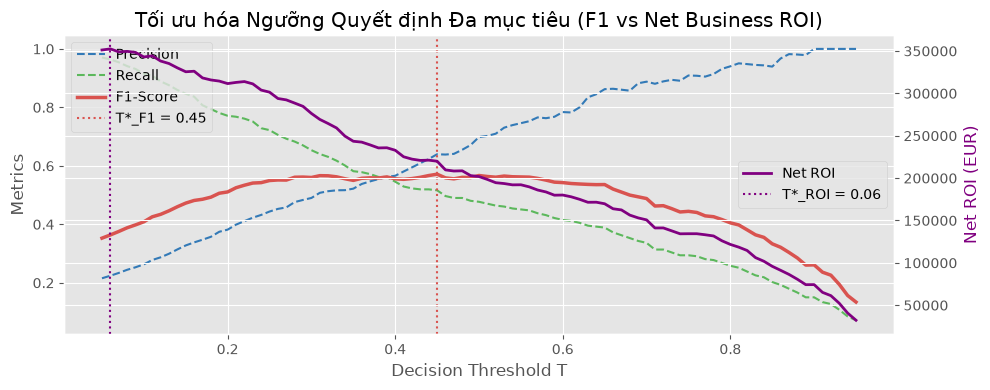

In [25]:
champion_pipe = trained_pipelines['XGBoost_StandardScaler']
val_probs = champion_pipe.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
t_records = []
best_f1, best_t_f1 = -1, 0.5
best_roi, best_t_roi = -np.inf, 0.5

val_balances = val_df['Balance'].values
y_val_arr = y_val.values

for t in thresholds:
    preds = (val_probs >= t).astype(int)
    f1 = f1_score(y_val_arr, preds, zero_division=0)
    prec = precision_score(y_val_arr, preds, zero_division=0)
    rec = recall_score(y_val_arr, preds, zero_division=0)
    
    # Financial Net Gain
    tp_mask = (y_val_arr == 1) & (preds == 1)
    saved_clv = np.sum((val_balances[tp_mask] * 0.05 + 200) * 0.30)
    targeted_cost = np.sum(preds == 1) * 50.0
    net_roi = saved_clv - targeted_cost
    
    if f1 > best_f1:
        best_f1 = f1
        best_t_f1 = t
    if net_roi > best_roi:
        best_roi = net_roi
        best_t_roi = t
        
    t_records.append({'Threshold': round(t, 2), 'Precision': prec, 'Recall': rec, 'F1': f1, 'Net_ROI_EUR': net_roi})

df_t_curve = pd.DataFrame(t_records)
print(f"Ngưỡng Tối ưu F1-Score: T*_F1 = {best_t_f1:.2f} (F1 = {best_f1:.4f})")
print(f"Ngưỡng Tối ưu Net ROI:  T*_ROI = {best_t_roi:.2f} (Net ROI = {best_roi:,.2f} EUR)")

# Vẽ biểu đồ tối ưu ngưỡng
fig, ax1 = plt.subplots(figsize=onefig_size)
ax1.plot(df_t_curve['Threshold'], df_t_curve['Precision'], label='Precision', color='#337ab7', linestyle='--')
ax1.plot(df_t_curve['Threshold'], df_t_curve['Recall'], label='Recall', color='#5cb85c', linestyle='--')
ax1.plot(df_t_curve['Threshold'], df_t_curve['F1'], label='F1-Score', color='#d9534f', linewidth=2.5)
ax1.axvline(x=best_t_f1, color='#d9534f', linestyle=':', label=f'T*_F1 = {best_t_f1:.2f}')
ax1.set_xlabel('Decision Threshold T')
ax1.set_ylabel('Metrics')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(df_t_curve['Threshold'], df_t_curve['Net_ROI_EUR'], label='Net ROI', color='purple', linewidth=2)
ax2.axvline(x=best_t_roi, color='purple', linestyle=':', label=f'T*_ROI = {best_t_roi:.2f}')
ax2.set_ylabel('Net ROI (EUR)', color='purple')
ax2.legend(loc='center right')
plt.title("Tối ưu hóa Ngưỡng Quyết định Đa mục tiêu (F1 vs Net Business ROI)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_16_threshold_tuning_curves.png'), dpi=300, bbox_inches='tight')
plt.show()


### Đánh giá 1 Lần Duy nhất trên Tập Kiểm thử (`test.csv` - 1,500 Khách hàng)

In [26]:
T_OPT = round(best_t_f1, 2)
test_probs = champion_pipe.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= T_OPT).astype(int)

# 1. Point metrics
test_acc = accuracy_score(y_test, test_preds)
test_prec = precision_score(y_test, test_preds, zero_division=0)
test_rec = recall_score(y_test, test_preds, zero_division=0)
test_f1 = f1_score(y_test, test_preds, zero_division=0)
test_auc = roc_auc_score(y_test, test_probs)
test_pr_auc = average_precision_score(y_test, test_probs)

# 2. 95% Bootstrap CI
rng = np.random.default_rng(42)
n_samples = len(y_test)
boot_aucs, boot_f1s = [], []
y_test_arr = y_test.values

for _ in range(1000):
    idx = rng.choice(n_samples, size=n_samples, replace=True)
    if len(np.unique(y_test_arr[idx])) < 2:
        continue
    b_p = test_probs[idx]
    b_pred = (b_p >= T_OPT).astype(int)
    boot_aucs.append(roc_auc_score(y_test_arr[idx], b_p))
    boot_f1s.append(f1_score(y_test_arr[idx], b_pred, zero_division=0))

auc_ci = (round(np.percentile(boot_aucs, 2.5), 4), round(np.percentile(boot_aucs, 97.5), 4))
f1_ci = (round(np.percentile(boot_f1s, 2.5), 4), round(np.percentile(boot_f1s, 97.5), 4))

print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (NGƯỠNG T = {T_OPT}) ===")
print(f" - Accuracy:  {test_acc:.4f}")
print(f" - Precision: {test_prec:.4f}")
print(f" - Recall:    {test_rec:.4f}")
print(f" - F1-Score:  {test_f1:.4f}  (95% Bootstrap CI: [{f1_ci[0]}, {f1_ci[1]}])")
print(f" - ROC-AUC:   {test_auc:.4f}   (95% Bootstrap CI: [{auc_ci[0]}, {auc_ci[1]}])")
print(f" - PR-AUC:    {test_pr_auc:.4f}")

# 3. Decile Lift Table
test_df_eval = pd.DataFrame({'Exited': y_test_arr, 'Probability': test_probs}).sort_values('Probability', ascending=False).reset_index(drop=True)
test_df_eval['Decile'] = pd.qcut(test_df_eval.index, q=10, labels=list(range(1, 11)))
total_churners = test_df_eval['Exited'].sum()
global_churn_rate = test_df_eval['Exited'].mean()

deciles = []
cum_churn = 0
for d in range(1, 11):
    sub = test_df_eval[test_df_eval['Decile'] == d]
    c_count = len(sub)
    c_churn = sub['Exited'].sum()
    cum_churn += c_churn
    gain = (cum_churn / total_churners) * 100.0
    lift = (cum_churn / (d * c_count)) / global_churn_rate
    deciles.append({
        'Decile': d,
        'Customers': c_count,
        'Churners': c_churn,
        'Decile_Churn_Rate_Pct': round(c_churn / c_count * 100, 2),
        'Cum_Churners': cum_churn,
        'Cum_Gain_Pct': round(gain, 2),
        'Cum_Lift': round(lift, 2)
    })

df_deciles = pd.DataFrame(deciles)
print("\n=== BẢNG DECILE GAIN & CUMULATIVE LIFT TRÊN TẬP TEST ===")
display(df_deciles)


=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (NGƯỠNG T = 0.45) ===
 - Accuracy:  0.8467
 - Precision: 0.6448
 - Recall:    0.5475
 - F1-Score:  0.5922  (95% Bootstrap CI: [0.5428, 0.6348])
 - ROC-AUC:   0.8437   (95% Bootstrap CI: [0.8179, 0.8693])
 - PR-AUC:    0.6621

=== BẢNG DECILE GAIN & CUMULATIVE LIFT TRÊN TẬP TEST ===


,Decile,Customers,Churners,Decile_Churn_Rate_Pct,Cum_Churners,Cum_Gain_Pct,Cum_Lift
0,1,150,121,80.67,121,39.67,3.97
1,2,150,61,40.67,182,59.67,2.98
2,3,150,39,26.00,221,72.46,2.42
3,4,150,25,16.67,246,80.66,2.02
4,5,150,20,13.33,266,87.21,1.74
5,6,150,12,8.00,278,91.15,1.52
6,7,150,11,7.33,289,94.75,1.35
7,8,150,7,4.67,296,97.05,1.21
8,9,150,4,2.67,300,98.36,1.09
9,10,150,5,3.33,305,100.00,1.00


### Giải thích Mô hình Bằng SHAP (Model Explainability)

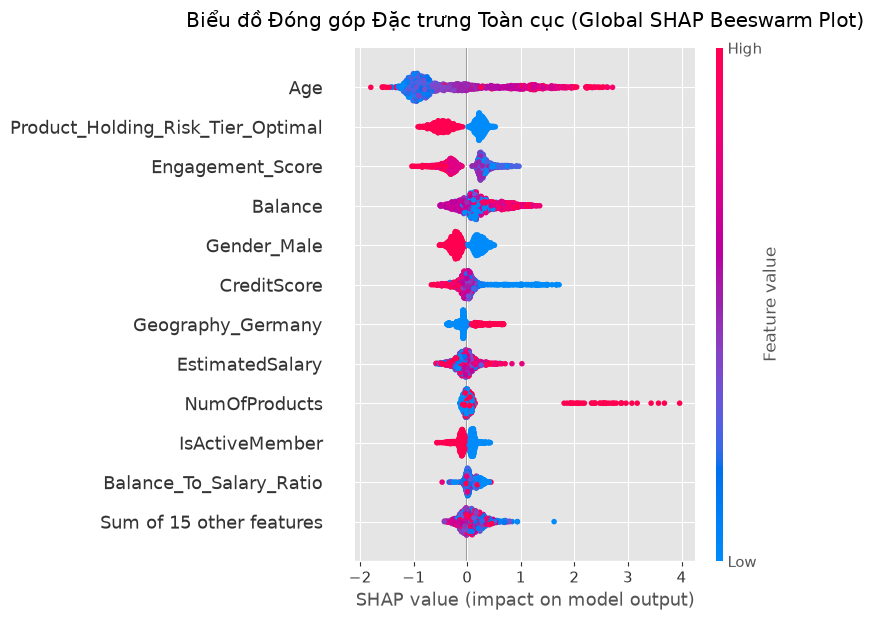

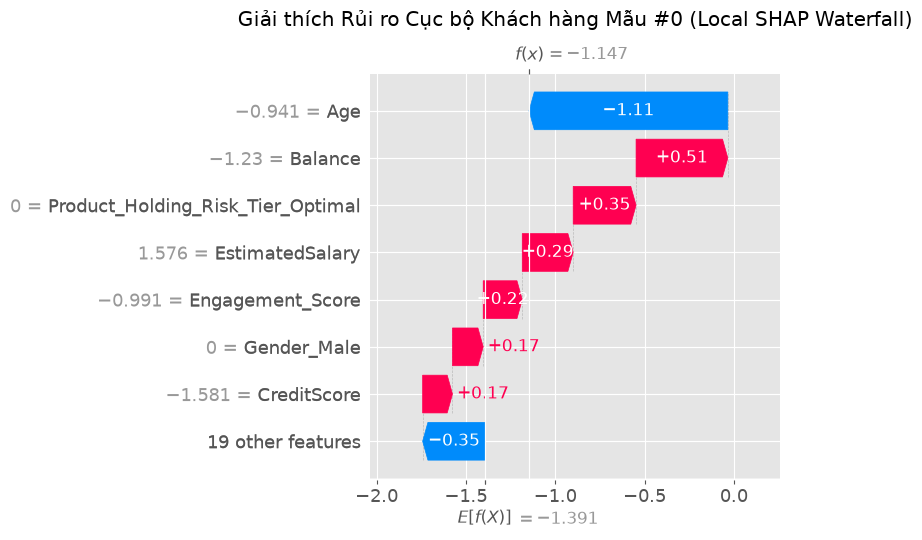

In [27]:
import shap

# Trích xuất preprocessor và model từ pipeline
preproc = champion_pipe.named_steps['preprocessor']
model_xgb = champion_pipe.named_steps['classifier']

X_test_trans = preproc.transform(X_test)
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer(X_test_trans)
shap_values.feature_names = cleaned_names

# 1. Global Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("Biểu đồ Đóng góp Đặc trưng Toàn cục (Global SHAP Beeswarm Plot)", pad=15)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_14_shap_summary.png'), dpi=300, bbox_inches='tight')
plt.show()

# 2. Local Waterfall Plot cho khách hàng mẫu #0
plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[0], max_display=8, show=False)
plt.title("Giải thích Rủi ro Cục bộ Khách hàng Mẫu #0 (Local SHAP Waterfall)", pad=15)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_15_shap_waterfall_sample.png'), dpi=300, bbox_inches='tight')
plt.show()


## Prescriptive Strategy & Tiered ROI
**Tầng 4 Phân tích Đề xuất (Prescriptive Analytics):**
Thiết lập ma trận phân khúc 4 góc phần tư (Giá trị $\times$ Rủi ro), Động cơ Next-Best-Action, Kịch bản cuộc gọi và Mô hình Lợi nhuận Ròng Đa tầng.


In [28]:
# 1. Phân khúc 4 góc phần tư trên toàn bộ 10,000 khách hàng
full_probs = champion_pipe.predict_proba(df_fe[numeric_cols + categorical_cols])[:, 1]
df_fe['Predicted_Probability'] = np.round(full_probs, 4)

# Quy tắc cứng cho khiếu nại (Hard Business Rule override)
df_fe.loc[df_fe['Complain'] == 1, 'Predicted_Probability'] = 0.9986

high_val = df_fe['Balance'] >= 80000.0
high_risk = df_fe['Predicted_Probability'] >= T_OPT

df_fe['Quadrant'] = np.select(
    [high_val & high_risk, (~high_val) & high_risk, high_val & (~high_risk), (~high_val) & (~high_risk)],
    ['Q1_VIP_At_Risk', 'Q2_Standard_At_Risk', 'Q3_VIP_Loyal', 'Q4_Standard_Loyal'],
    default='Q4_Standard_Loyal'
)

q_summary = df_fe.groupby('Quadrant').agg(
    Customer_Count=('CustomerId', 'count'),
    Customer_Pct=('CustomerId', lambda x: round(len(x)/len(df_fe)*100, 2)),
    Total_Balance_M_EUR=('Balance', lambda x: round(x.sum()/1e6, 2)),
    Mean_Balance_EUR=('Balance', lambda x: round(x.mean(), 2)),
    Avg_Predicted_Risk_Pct=('Predicted_Probability', lambda x: round(x.mean()*100, 2)),
    Actual_Churn_Pct=('Exited', lambda x: round(x.mean()*100, 2))
).reset_index()

print("=== BẢNG PHÂN KHÚC 4 GÓC PHẦN TƯ TOÀN NGÂN HÀNG ===")
display(q_summary)


=== BẢNG PHÂN KHÚC 4 GÓC PHẦN TƯ TOÀN NGÂN HÀNG ===


,Quadrant,Customer_Count,Customer_Pct,Total_Balance_M_EUR,Mean_Balance_EUR,Avg_Predicted_Risk_Pct,Actual_Churn_Pct
0,Q1_VIP_At_Risk,1899,18.99,242.81,127863.67,90.180000,74.14
1,Q2_Standard_At_Risk,754,7.54,9.32,12358.96,93.349998,83.29
2,Q3_VIP_Loyal,3899,38.99,483.73,124064.85,16.000000,0.03
3,Q4_Standard_Loyal,3448,34.48,29.00,8410.18,13.420000,0.03


### Động cơ Next-Best-Action (NBA) & Kịch bản Cuộc gọi Chăm sóc Khách hàng

In [29]:
def get_nba_recommendation(row):
    if row.get('Complain', 0) == 1:
        return {
            'Strategy': 'S1: Xử lý Khiếu nại Khẩn cấp (SLA 4-Hour Escalation)',
            'Action': 'Quản lý Chi nhánh gọi trực tiếp trong 4h, giải quyết khiếu nại, hoàn 100% phí phát sinh, miễn phí VIP 6 tháng.',
            'Cost_EUR': 200.0
        }
    elif row.get('NumOfProducts', 1) >= 3:
        return {
            'Strategy': 'S2: Gỡ bẫy Bán chéo & Hợp nhất Sản phẩm',
            'Action': 'Chuyên viên RM liên hệ tinh gọn danh mục 3-4 sp về Combo 2 sp tối ưu, hủy thẻ phụ, hoàn phí thường niên năm gần nhất.',
            'Cost_EUR': 100.0
        }
    elif row.get('Geography') == 'Germany' and row.get('Balance', 0) >= 80000.0:
        return {
            'Strategy': 'S3: Bảo toàn Dòng vốn Chi nhánh Đức',
            'Action': 'Chỉ định Private Banker, đề xuất gói tiền gửi linh hoạt lãi suất ưu đãi +0.50%/năm cạnh tranh với ngân hàng nội địa.',
            'Cost_EUR': 150.0
        }
    elif row.get('IsActiveMember', 1) == 0:
        return {
            'Strategy': 'S4: Tái kích hoạt Kênh số (Digital Re-engagement)',
            'Action': 'Gửi Push Notification App + Email tặng voucher 20 EUR cho giao dịch đầu tiên qua App Mobile.',
            'Cost_EUR': 20.0
        }
    else:
        return {
            'Strategy': 'S5: Tri ân & Rà soát Danh mục Thường niên',
            'Action': 'Tặng 500 điểm thưởng Loyalty và mời rà soát sức khỏe tài chính định kỳ tại quầy VIP.',
            'Cost_EUR': 25.0
        }

# Minh họa cho 3 khách hàng điển hình
for idx in [0, 4, 16]:
    sample_c = df_fe.iloc[idx].to_dict()
    nba = get_nba_recommendation(sample_c)
    print(f"\n--- Khách hàng #{sample_c['CustomerId']} ({sample_c['Surname']}) ---")
    print(f"Quốc gia: {sample_c['Geography']} | Số dư: {sample_c['Balance']:,.2f} EUR | SP: {sample_c['NumOfProducts']} | Churn Prob: {sample_c['Predicted_Probability']*100:.1f}%")
    print(f" -> Chiến lược: {nba['Strategy']}")
    print(f" -> Hành động đề xuất: {nba['Action']}")



--- Khách hàng #15634602 (Hargrave) ---
Quốc gia: France | Số dư: 0.00 EUR | SP: 1 | Churn Prob: 99.9%
 -> Chiến lược: S1: Xử lý Khiếu nại Khẩn cấp (SLA 4-Hour Escalation)
 -> Hành động đề xuất: Quản lý Chi nhánh gọi trực tiếp trong 4h, giải quyết khiếu nại, hoàn 100% phí phát sinh, miễn phí VIP 6 tháng.

--- Khách hàng #15737888 (Mitchell) ---
Quốc gia: Spain | Số dư: 125,510.82 EUR | SP: 1 | Churn Prob: 20.8%
 -> Chiến lược: S5: Tri ân & Rà soát Danh mục Thường niên
 -> Hành động đề xuất: Tặng 500 điểm thưởng Loyalty và mời rà soát sức khỏe tài chính định kỳ tại quầy VIP.

--- Khách hàng #15737452 (Romeo) ---
Quốc gia: Germany | Số dư: 132,602.88 EUR | SP: 1 | Churn Prob: 93.3%
 -> Chiến lược: S3: Bảo toàn Dòng vốn Chi nhánh Đức
 -> Hành động đề xuất: Chỉ định Private Banker, đề xuất gói tiền gửi linh hoạt lãi suất ưu đãi +0.50%/năm cạnh tranh với ngân hàng nội địa.


### Mô phỏng Lợi nhuận Ròng Đa tầng (Tiered Financial ROI)

In [30]:
# Tính toán ROI cho Q1 (VIP) và Q2 (Standard)
q1_df = df_fe[df_fe['Quadrant'] == 'Q1_VIP_At_Risk']
q2_df = df_fe[df_fe['Quadrant'] == 'Q2_Standard_At_Risk']

# Q1
q1_count = len(q1_df)
q1_cost = q1_count * 150.0
q1_saved_cust = q1_df['Exited'].sum() * 0.40
q1_saved_bal = (q1_df['Balance'].sum() / q1_count * q1_saved_cust)
q1_clv = q1_saved_bal * 0.05 + (q1_saved_cust * 200)
q1_net = q1_clv - q1_cost
q1_roi = (q1_net / q1_cost) * 100.0

# Q2
q2_count = len(q2_df)
q2_cost = q2_count * 25.0
q2_saved_cust = q2_df['Exited'].sum() * 0.25
q2_saved_bal = (q2_df['Balance'].sum() / q2_count * q2_saved_cust)
q2_clv = q2_saved_bal * 0.05 + (q2_saved_cust * 200)
q2_net = q2_clv - q2_cost
q2_roi = (q2_net / q2_cost) * 100.0

tot_cost = q1_cost + q2_cost
tot_saved_cust = q1_saved_cust + q2_saved_cust
tot_saved_bal = q1_saved_bal + q2_saved_bal
tot_clv = q1_clv + q2_clv
tot_net = tot_clv - tot_cost
tot_roi = (tot_net / tot_cost) * 100.0

df_roi_final = pd.DataFrame([
    {
        'Chiến dịch': 'Q1: VIP Nguy cơ Cao (High Value, High Risk)',
        'Khách tiếp cận': f"{q1_count:,}",
        'Chi phí': f"{q1_cost:,.2f} EUR",
        'Khách giữ lại': f"{q1_saved_cust:.1f}",
        'Vốn bảo toàn': f"{q1_saved_bal/1e6:.2f}M EUR",
        'Giá trị CLV': f"{q1_clv:,.2f} EUR",
        'Lợi nhuận Ròng': f"{q1_net:,.2f} EUR",
        'Tỷ suất ROI': f"{q1_roi:.1f}%"
    },
    {
        'Chiến dịch': 'Q2: Phổ thông Nguy cơ Cao (Low Value, High Risk)',
        'Khách tiếp cận': f"{q2_count:,}",
        'Chi phí': f"{q2_cost:,.2f} EUR",
        'Khách giữ lại': f"{q2_saved_cust:.1f}",
        'Vốn bảo toàn': f"{q2_saved_bal/1e6:.2f}M EUR",
        'Giá trị CLV': f"{q2_clv:,.2f} EUR",
        'Lợi nhuận Ròng': f"{q2_net:,.2f} EUR",
        'Tỷ suất ROI': f"{q2_roi:.1f}%"
    },
    {
        'Chiến dịch': 'TOÀN BỘ CHIẾN DỊCH (TOTAL PORTFOLIO)',
        'Khách tiếp cận': f"{q1_count + q2_count:,}",
        'Chi phí': f"{tot_cost:,.2f} EUR",
        'Khách giữ lại': f"{tot_saved_cust:.1f}",
        'Vốn bảo toàn': f"{tot_saved_bal/1e6:.2f}M EUR",
        'Giá trị CLV': f"{tot_clv:,.2f} EUR",
        'Lợi nhuận Ròng': f"{tot_net:,.2f} EUR",
        'Tỷ suất ROI': f"{tot_roi:.1f}%"
    }
])
display(df_roi_final)


,Chiến dịch,Khách tiếp cận,Chi phí,Khách giữ lại,Vốn bảo toàn,Giá trị CLV,Lợi nhuận Ròng,Tỷ suất ROI
0,"Q1: VIP Nguy cơ Cao (High Value, High Risk)","1,899","284,850.00 EUR",563.2,72.01M EUR,"3,713,280.86 EUR","3,428,430.86 EUR",1203.6%
1,"Q2: Phổ thông Nguy cơ Cao (Low Value, High Risk)",754,"18,850.00 EUR",157.0,1.94M EUR,"128,417.81 EUR","109,567.81 EUR",581.3%
2,TOÀN BỘ CHIẾN DỊCH (TOTAL PORTFOLIO),"2,653","303,700.00 EUR",720.2,73.95M EUR,"3,841,698.67 EUR","3,537,998.67 EUR",1165.0%


### Đóng gói Mô hình & Lưu trữ Metadata Quản trị

In [31]:
import joblib
import sklearn
import xgboost

# 1. Lưu Pipeline quán quân
pipeline_export_path = os.path.join(MODELS_DIR, 'churn_early_warning_pipeline.joblib')
joblib.dump(champion_pipe, pipeline_export_path)
print(f"Đã lưu Champion Pipeline tại: {pipeline_export_path}")

# 2. Lưu Metadata quản trị phiên bản
metadata_dict = {
    'model_name': 'XGBoost_StandardScaler_Proactive',
    'champion_model_type': 'XGBClassifier',
    'scaler': 'StandardScaler',
    'target_column': 'Exited',
    'excluded_features_target_leakage': ['Complain'],
    'feature_columns': numeric_cols + categorical_cols,
    'optimal_decision_threshold': float(T_OPT),
    'test_holdout_metrics': {
        'accuracy': float(test_acc),
        'precision': float(test_prec),
        'recall': float(test_rec),
        'f1_score': float(test_f1),
        'f1_95_ci': [float(x) for x in f1_ci],
        'roc_auc': float(test_auc),
        'roc_auc_95_ci': [float(x) for x in auc_ci],
        'pr_auc': float(test_pr_auc)
    },
    'runtime_environment': {
        'python_version': sys.version.split()[0],
        'scikit_learn_version': sklearn.__version__,
        'xgboost_version': xgboost.__version__,
        'joblib_version': joblib.__version__
    }
}

metadata_export_path = os.path.join(MODELS_DIR, 'model_metadata.json')
with open(metadata_export_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_dict, f, indent=4, ensure_ascii=False)

print(f"Đã lưu Metadata tại: {metadata_export_path}")
print("\n=== HOÀN TẤT TOÀN BỘ QUY TRÌNH HỌC MÁY TRONG 1 FILE NOTEBOOK DUY NHẤT! ===")


Đã lưu Champion Pipeline tại: models\churn_early_warning_pipeline.joblib
Đã lưu Metadata tại: models\model_metadata.json

=== HOÀN TẤT TOÀN BỘ QUY TRÌNH HỌC MÁY TRONG 1 FILE NOTEBOOK DUY NHẤT! ===
